# Wine classification with separate analysis of text and than clustering of all features including constructed from text

In [3]:
#pip install -U sentence-transformers

In [1]:
# import
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import umap

from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn import decomposition

W1021 13:52:07.233000 2429 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [12]:
# loading data
wine = pd.read_csv('../winemag-data_first150k.csv', index_col=[0])
wine

,country,description,designation,points,price,province,region_1,region_2,variety,winery
0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Napa,Cabernet Sauvignon,Heitz
1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sonoma,Sauvignon Blanc,Macauley
3,US,"This spent 20 months in 30% new French oak, an...",Reserve,96,65.0,Oregon,Willamette Valley,Willamette Valley,Pinot Noir,Ponzi
4,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,NaN,Provence red blend,Domaine de la Bégude
...,...,...,...,...,...,...,...,...,...,...
150925,Italy,Many people feel Fiano represents southern Ita...,NaN,91,20.0,Southern Italy,Fiano di Avellino,NaN,White Blend,Feudi di San Gregorio
150926,France,"Offers an intriguing nose with ginger, lime an...",Cuvée Prestige,91,27.0,Champagne,Champagne,NaN,Champagne Blend,H.Germain
150927,Italy,This classic example comes from a cru vineyard...,Terre di Dora,91,20.0,Southern Italy,Fiano di Avellino,NaN,White Blend,Terredora
150928,France,"A perfect salmon shade, with scents of peaches...",Grand Brut Rosé,90,52.0,Champagne,Champagne,NaN,Champagne Blend,Gosset


In [13]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150930 entries, 0 to 150929
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   country      150925 non-null  object 
 1   description  150930 non-null  object 
 2   designation  105195 non-null  object 
 3   points       150930 non-null  int64  
 4   price        137235 non-null  float64
 5   province     150925 non-null  object 
 6   region_1     125870 non-null  object 
 7   region_2     60953 non-null   object 
 8   variety      150930 non-null  object 
 9   winery       150930 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 12.7+ MB


In [14]:
wine.describe()

,points,price
count,150930.000000,137235.000000
mean,87.888418,33.131482
std,3.222392,36.322536
min,80.000000,4.000000
25%,86.000000,16.000000
50%,88.000000,24.000000
75%,90.000000,40.000000
max,100.000000,2300.000000


In [15]:
wine.describe(include='object')

,country,description,designation,province,region_1,region_2,variety,winery
count,150925,150930,105195,150925,125870,60953,150930,150930
unique,48,97821,30621,455,1236,18,632,14810
top,US,A little bit funky and unsettled when you pop ...,Reserve,California,Napa Valley,Central Coast,Chardonnay,Williams Selyem
freq,62397,6,2752,44508,6209,13057,14482,374


In [16]:
wine.country.value_counts().to_frame()['count'][:6]

country
US           62397
Italy        23478
France       21098
Spain         8268
Chile         5816
Argentina     5631
Name: count, dtype: int64

Data from US more detailed but there are unproporcial with Eurpoean datasets and it looks like datasets with different origin i'll use only three main wine european countries

In [17]:
wine = wine.loc[wine['country'].isin(['Italy', 'France', 'Spain'])]
wine.info()

<class 'pandas.core.frame.DataFrame'>
Index: 52844 entries, 1 to 150929
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      52844 non-null  object 
 1   description  52844 non-null  object 
 2   designation  37951 non-null  object 
 3   points       52844 non-null  int64  
 4   price        41729 non-null  float64
 5   province     52844 non-null  object 
 6   region_1     52829 non-null  object 
 7   region_2     0 non-null      object 
 8   variety      52844 non-null  object 
 9   winery       52844 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 4.4+ MB


For my goals i always need in description and i think i can skip Nones from price, and i don't need region_2 as well as columns used only for US data

In [18]:
wine = wine.drop('region_2',axis=1)
wine = wine.dropna(subset='price')
wine.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41729 entries, 1 to 150929
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      41729 non-null  object 
 1   description  41729 non-null  object 
 2   designation  29881 non-null  object 
 3   points       41729 non-null  int64  
 4   price        41729 non-null  float64
 5   province     41729 non-null  object 
 6   region_1     41719 non-null  object 
 7   variety      41729 non-null  object 
 8   winery       41729 non-null  object 
dtypes: float64(1), int64(1), object(7)
memory usage: 3.2+ MB


In [19]:
# fill nones in designation from winery + variety
wine['designation'] = wine['designation'].fillna('NO_NAME')
wine = wine.reset_index(drop=True)
wine

,country,description,designation,points,price,province,region_1,variety,winery
0,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,Tinta de Toro,Bodega Carmen Rodríguez
1,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,Provence red blend,Domaine de la Bégude
2,Spain,"Deep, dense and pure from the opening bell, th...",Numanthia,95,73.0,Northern Spain,Toro,Tinta de Toro,Numanthia
3,Spain,Slightly gritty black-fruit aromas include a s...,San Román,95,65.0,Northern Spain,Toro,Tinta de Toro,Maurodos
4,Spain,Lush cedary black-fruit aromas are luxe and of...,Carodorum Único Crianza,95,110.0,Northern Spain,Toro,Tinta de Toro,Bodega Carmen Rodríguez
...,...,...,...,...,...,...,...,...,...
41724,Italy,Many people feel Fiano represents southern Ita...,NO_NAME,91,20.0,Southern Italy,Fiano di Avellino,White Blend,Feudi di San Gregorio
41725,France,"Offers an intriguing nose with ginger, lime an...",Cuvée Prestige,91,27.0,Champagne,Champagne,Champagne Blend,H.Germain
41726,Italy,This classic example comes from a cru vineyard...,Terre di Dora,91,20.0,Southern Italy,Fiano di Avellino,White Blend,Terredora
41727,France,"A perfect salmon shade, with scents of peaches...",Grand Brut Rosé,90,52.0,Champagne,Champagne,Champagne Blend,Gosset


In [20]:
def winery_to_desc(row):
    des = row['designation']
    win = row['winery']
    var = row['variety']
    if des == 'NO_NAME':
        return win + ' ' + var
    else:
        return des

wine['designation'] = wine.apply(winery_to_desc, axis=1)
wine

,country,description,designation,points,price,province,region_1,variety,winery
0,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,Tinta de Toro,Bodega Carmen Rodríguez
1,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,Provence red blend,Domaine de la Bégude
2,Spain,"Deep, dense and pure from the opening bell, th...",Numanthia,95,73.0,Northern Spain,Toro,Tinta de Toro,Numanthia
3,Spain,Slightly gritty black-fruit aromas include a s...,San Román,95,65.0,Northern Spain,Toro,Tinta de Toro,Maurodos
4,Spain,Lush cedary black-fruit aromas are luxe and of...,Carodorum Único Crianza,95,110.0,Northern Spain,Toro,Tinta de Toro,Bodega Carmen Rodríguez
...,...,...,...,...,...,...,...,...,...
41724,Italy,Many people feel Fiano represents southern Ita...,Feudi di San Gregorio White Blend,91,20.0,Southern Italy,Fiano di Avellino,White Blend,Feudi di San Gregorio
41725,France,"Offers an intriguing nose with ginger, lime an...",Cuvée Prestige,91,27.0,Champagne,Champagne,Champagne Blend,H.Germain
41726,Italy,This classic example comes from a cru vineyard...,Terre di Dora,91,20.0,Southern Italy,Fiano di Avellino,White Blend,Terredora
41727,France,"A perfect salmon shade, with scents of peaches...",Grand Brut Rosé,90,52.0,Champagne,Champagne,Champagne Blend,Gosset


In [21]:
# look to most popular varieties from this dataset
wine.variety.value_counts().to_frame().head(20)

,count
variety,
Red Blend,4408
Chardonnay,2862
Sangiovese,2258
Bordeaux-style Red Blend,2202
Tempranillo,2119
Pinot Noir,1602
Nebbiolo,1479
Rosé,1398
White Blend,1386


In [22]:
# look to most frequent regions from this dataset
wine.region_1.value_counts().to_frame().head(20)

,count
region_1,
Rioja,1884
Toscana,1660
Sicilia,1364
Brunello di Montalcino,1305
Alsace,1261
Champagne,1088
Barolo,925
Ribera del Duero,865
Chianti Classico,835


In [23]:
selected_var = wine.variety.value_counts().to_frame().index[:10].to_list()
print(selected_var)

# use only 10 most popular varieties
wine = wine.loc[wine['variety'].isin(selected_var)]
wine.info()

['Red Blend', 'Chardonnay', 'Sangiovese', 'Bordeaux-style Red Blend', 'Tempranillo', 'Pinot Noir', 'Nebbiolo', 'Rosé', 'White Blend', 'Corvina, Rondinella, Molinara']
<class 'pandas.core.frame.DataFrame'>
Index: 21006 entries, 7 to 41726
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      21006 non-null  object 
 1   description  21006 non-null  object 
 2   designation  21006 non-null  object 
 3   points       21006 non-null  int64  
 4   price        21006 non-null  float64
 5   province     21006 non-null  object 
 6   region_1     21003 non-null  object 
 7   variety      21006 non-null  object 
 8   winery       21006 non-null  object 
dtypes: float64(1), int64(1), object(7)
memory usage: 1.6+ MB


In [24]:
color_dict = {'Pinot Noir':'red', 'Rosé':'red', 'Chardonnay':'white', 'Sangiovese': 'red', 'Tempranillo':'red', \
              'Nebbiolo':'red','White Blend':'white','Red Blend':'red','Bordeaux-style Red Blend':'red','Corvina, Rondinella, Molinara':'red'}
print(color_dict)

# red and white wine
wine['color'] = wine['variety'].map(color_dict)

wine['color'].value_counts()

{'Pinot Noir': 'red', 'Rosé': 'red', 'Chardonnay': 'white', 'Sangiovese': 'red', 'Tempranillo': 'red', 'Nebbiolo': 'red', 'White Blend': 'white', 'Red Blend': 'red', 'Bordeaux-style Red Blend': 'red', 'Corvina, Rondinella, Molinara': 'red'}


/var/folders/4c/hjs_wdj51j582vlxww6jc4fr0000gn/T/ipykernel_2429/3867668023.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wine['color'] = wine['variety'].map(color_dict)


color
red      16758
white     4248
Name: count, dtype: int64

{'whiskers': [<matplotlib.lines.Line2D at 0x3795d52d0>,
 'caps': [<matplotlib.lines.Line2D at 0x3795d6750>,
 'boxes': [<matplotlib.lines.Line2D at 0x37929d210>],
 'medians': [<matplotlib.lines.Line2D at 0x3795d7850>],
 'fliers': [<matplotlib.lines.Line2D at 0x3795e4110>],
 'means': []}

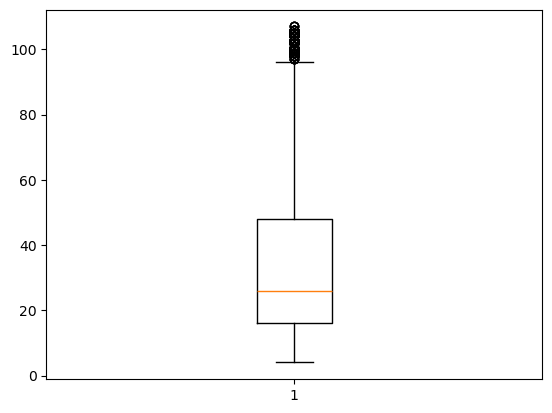

In [39]:
# and i want to clean outliers from price, so high prices looks as real prices just expensive, but for this dataset i don't want to use data with small but very different cluster (high prices)

plt.boxplot(wine['price'])

In [27]:
# i want to comapre approaches to clean outliers - throw iqr and throw mad
from scipy.stats import iqr
from scipy.stats import median_abs_deviation

iqr_wine = iqr(wine['price'])
qntl_25 = wine['price'].quantile(0.25)
qntl_75 = wine['price'].quantile(0.75)
median_wine = np.median( wine['price'])
mad_wine = median_abs_deviation( wine['price'])
print(iqr_wine, median_wine, mad_wine)

36.0 29.0 14.0


In [28]:
iqr_outlier = wine['price'].apply(lambda x: True if (x > (qntl_75 + 1.5*iqr_wine) or x < (qntl_25 - 1.5*iqr_wine)) else False)
print(np.sum(iqr_outlier))
mad_outlier = wine['price'].apply(lambda x: True if (np.abs(0.6475 * (x - median_wine) / mad_wine) > 3.5) else False)
print(np.sum(mad_outlier))

1213
1285


In [29]:
wine['outliers'] = iqr_outlier
wine = wine.loc[wine['outliers'] == False]
wine = wine.drop('outliers', axis=1)
wine.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19793 entries, 7 to 41726
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      19793 non-null  object 
 1   description  19793 non-null  object 
 2   designation  19793 non-null  object 
 3   points       19793 non-null  int64  
 4   price        19793 non-null  float64
 5   province     19793 non-null  object 
 6   region_1     19790 non-null  object 
 7   variety      19793 non-null  object 
 8   winery       19793 non-null  object 
 9   color        19793 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 1.7+ MB


/var/folders/4c/hjs_wdj51j582vlxww6jc4fr0000gn/T/ipykernel_2429/3297598803.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wine['outliers'] = iqr_outlier


{'whiskers': [<matplotlib.lines.Line2D at 0x379636110>,
 'caps': [<matplotlib.lines.Line2D at 0x379637550>,
 'boxes': [<matplotlib.lines.Line2D at 0x379635790>],
 'medians': [<matplotlib.lines.Line2D at 0x379648590>],
 'fliers': [<matplotlib.lines.Line2D at 0x379648e50>],
 'means': []}

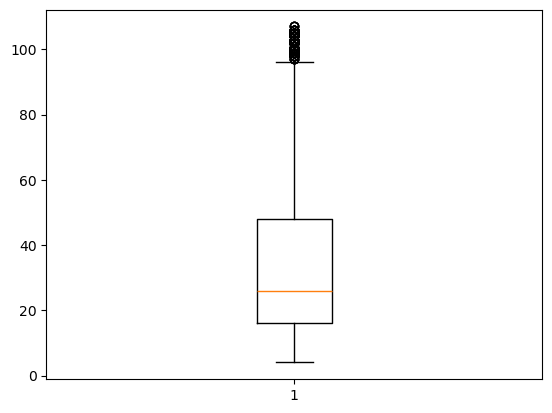

In [40]:
plt.boxplot(wine['price'])

Than visualistion of varieties by countries

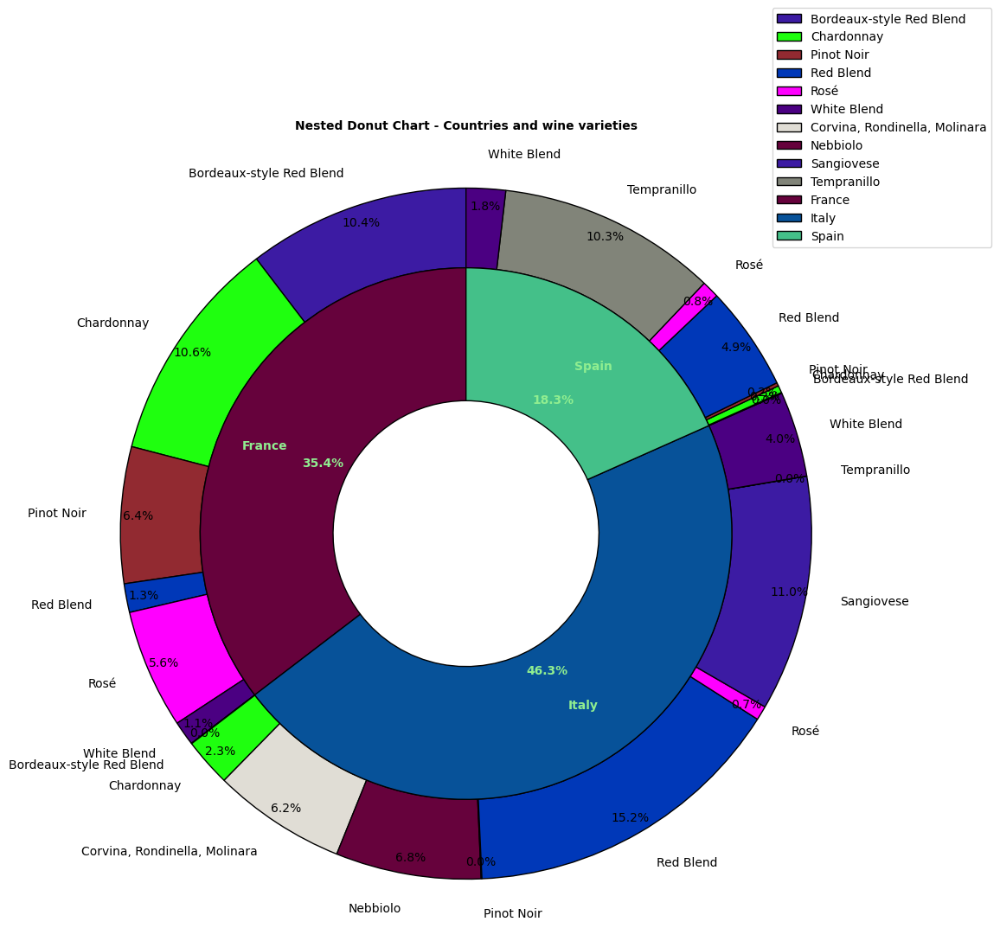

In [ ]:
# double pie (donut) plot for show how many objects belongs to three countries and how much inside of each of countries belongs to different varieties

wine_a = wine.groupby(['country','variety'])['price'].agg(['count']).reset_index()
wine_b = wine_a.groupby(['country'])['count'].agg(['sum']).reset_index()
wine_b

group_names = list(wine_b['country'])
group_sizes = list(wine_b['sum'])

subgroup_names = list(wine_a['variety'])
subgroup_sizes = list(wine_a['count'])


colors_inner = ['#66023C', '#075299', '#44C089']

unique_varieties = wine_a['variety'].unique()
cmap = plt.get_cmap('tab20')
variety_colors_dict = {variety: cmap(i) for i, variety in enumerate(unique_varieties)}

my_custom_colors = ['#3c1ba3', '#1FFF0F', '#922A31', '#0038B8', '#FF00FF', '#4B0082', '#e0ddd5', '#66023C','#3C1BA3','#818479']
variety_colors_dict = {variety: my_custom_colors[i % len(my_custom_colors)] for i, variety in enumerate(unique_varieties)}

colors_outer = [variety_colors_dict[v] for v in subgroup_names]


fig, ax = plt.subplots(figsize=(12, 12))

# Outer Ring (Subgroups)
ax.pie(subgroup_sizes,
       labels=subgroup_names,
       radius=1.3,              # Larger radius places it on the outside
       colors=colors_outer,
       startangle=90,
       pctdistance=0.95,
       autopct='%1.1f%%',
       wedgeprops=dict(width=0.3, edgecolor='black')) # width=0.3 creates the donut hole

# Inner Ring (Large Groups)
ax.pie(group_sizes,
       labels=group_names,
       labeldistance=0.75,
       radius=1.0,
       colors=colors_inner,
       startangle=90,
       autopct='%1.1f%%',
       pctdistance=0.60,
       textprops=dict(color="lightgreen", weight="bold"),
       wedgeprops=dict(width=0.5, edgecolor='black'))



ax.set(aspect="equal")
plt.title("Nested Donut Chart - Countries and wine varieties", pad=60, weight='bold', size=10)

# correction of legend to unique categories
handles, labels = ax.get_legend_handles_labels()
unique_labels = dict(zip(labels, handles))
ax.legend(unique_labels.values(), unique_labels.keys(), loc="upper right", bbox_to_anchor=(1.3, 1.3))

plt.tight_layout()
plt.savefig('01_2_donut_plot.jpg')
plt.show()

In [43]:
# i'll use this cols for visualisation (index reseted for comfortable operation using few dataframes)
wine = wine[['description','designation','points','price','variety','color','country']].reset_index(drop=True)
wine

,description,designation,points,price,variety,color,country
0,"Nicely oaked blackberry, licorice, vanilla and...",6 Años Reserva Premium,95,80.0,Tempranillo,red,Spain
1,"Aromas of forest floor, violet, red berry and ...",Avignonesi Sangiovese,90,29.0,Sangiovese,red,Italy
2,"This has a charming nose that boasts rose, vio...",Casina di Cornia Sangiovese,90,23.0,Sangiovese,red,Italy
3,"This bright, savory wine delivers aromas and f...",Riserva,90,29.0,Red Blend,red,Italy
4,"Aromas of dark-skinned berry, rose and wild he...",Riserva,90,39.0,Red Blend,red,Italy
...,...,...,...,...,...,...,...
19788,Scents of graham cracker and malted milk choco...,Michel Gros Pinot Noir,89,38.0,Pinot Noir,red,France
19789,"This needs a good bit of breathing time, then ...",Les Chaliots,87,37.0,Pinot Noir,red,France
19790,The nose is dominated by the attractive scents...,Les Charmes,87,65.0,Pinot Noir,red,France
19791,Many people feel Fiano represents southern Ita...,Feudi di San Gregorio White Blend,91,20.0,White Blend,white,Italy


In [44]:
# this case was preprared in option to use not only text embeddings in umap
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

cols_number = ['points', 'price']
col_ohe_a = ['variety']
col_ohe_b = ['color']
ct = ColumnTransformer(
    [("StandardScaler", StandardScaler(), cols_number),
     ("OHE_a", OneHotEncoder(drop='first'), col_ohe_b),
    # ("OHE_b", OneHotEncoder(drop='first'), col_ohe_b)
     ], verbose_feature_names_out=False)

In [45]:
try:
    # few ohe cols and sparse matrix
    transformed = pd.DataFrame.sparse.from_spmatrix(data=ct.fit_transform(wine), index=wine.index, columns=ct.get_feature_names_out())
except:
    # one ohe col
    transformed = pd.DataFrame(data=ct.fit_transform(wine), index=wine.index, columns=ct.get_feature_names_out())
    transformed

## text processing (only description col)

In [46]:
model = SentenceTransformer('all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [47]:
embeddings_list = model.encode(wine['description'].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/619 [00:00<?, ?it/s]

In [48]:
wine['embeddings'] = list(embeddings_list)
wine

,description,designation,points,price,variety,color,country,embeddings
0,"Nicely oaked blackberry, licorice, vanilla and...",6 Años Reserva Premium,95,80.0,Tempranillo,red,Spain,"[-0.062060844, -0.048369907, -0.019749388, 0.0..."
1,"Aromas of forest floor, violet, red berry and ...",Avignonesi Sangiovese,90,29.0,Sangiovese,red,Italy,"[0.053142738, -0.07310182, -0.024559004, 0.079..."
2,"This has a charming nose that boasts rose, vio...",Casina di Cornia Sangiovese,90,23.0,Sangiovese,red,Italy,"[0.013809526, -0.06623665, 0.021275952, 0.0714..."
3,"This bright, savory wine delivers aromas and f...",Riserva,90,29.0,Red Blend,red,Italy,"[-0.00071668037, -0.06365508, -0.018813752, 0...."
4,"Aromas of dark-skinned berry, rose and wild he...",Riserva,90,39.0,Red Blend,red,Italy,"[-0.0014956177, -0.046959206, 0.017721318, 0.0..."
...,...,...,...,...,...,...,...,...
19788,Scents of graham cracker and malted milk choco...,Michel Gros Pinot Noir,89,38.0,Pinot Noir,red,France,"[-0.060442157, -0.07200991, 0.087793574, 0.063..."
19789,"This needs a good bit of breathing time, then ...",Les Chaliots,87,37.0,Pinot Noir,red,France,"[-0.006190938, -0.01589112, 0.004324162, 0.013..."
19790,The nose is dominated by the attractive scents...,Les Charmes,87,65.0,Pinot Noir,red,France,"[0.08468355, -0.024974657, 0.031163542, -0.012..."
19791,Many people feel Fiano represents southern Ita...,Feudi di San Gregorio White Blend,91,20.0,White Blend,white,Italy,"[0.008319045, -0.0023741797, -0.031065125, 0.0..."


In [49]:
# prepare embedded data
X = np.vstack(wine['embeddings'].values)

In [50]:
# reduce text step1 (to 100 principal components)
pca = PCA(n_components=100)
pca_results = pca.fit_transform(X)

pca_results

array([[ 1.42908320e-02, -3.23188305e-03,  5.25959879e-02, ...,
         2.18246132e-04,  2.69191191e-02,  3.75062153e-02],
       [-2.70507067e-01, -8.88824463e-03,  1.83999464e-01, ...,
         2.44485177e-02, -3.81084159e-02,  1.27945300e-02],
       [-3.03873718e-01, -8.74470174e-02,  1.22293875e-01, ...,
         5.46837635e-02,  8.09533894e-03, -2.92907581e-02],
       ...,
       [-2.23949954e-01,  1.12964809e-02,  2.08642110e-01, ...,
         3.76561172e-02,  6.60702959e-03, -1.29743619e-02],
       [ 1.60073563e-02,  3.31223071e-01, -1.57114536e-01, ...,
        -9.70874578e-02, -1.01950042e-01, -1.08325109e-02],
       [-1.34354562e-01,  2.58233845e-01, -1.47388577e-01, ...,
        -5.00993803e-03, -2.96574924e-02, -1.44645143e-02]], dtype=float32)

In [51]:
# reduce text step2 (to 2 components with UMAP)
reducer = umap.UMAP()
embedding = reducer.fit_transform(pca_results)

Z = pd.DataFrame(
    embedding,
    columns=["component_1", "component_2"]
)
Z

/Users/vladkozlovskiy/anaconda3/lib/python3.11/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/vladkozlovskiy/anaconda3/lib/python3.11/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


,component_1,component_2
0,13.641759,3.800342
1,15.510157,1.707048
2,14.745640,-0.290869
3,15.492988,1.309125
4,14.813223,-0.467947
...,...,...
19788,11.913363,-0.200950
19789,13.322498,1.638076
19790,13.137674,-0.492893
19791,9.426954,3.261505


In [52]:
transformed['emb_1'] = Z["component_1"]
transformed['emb_2'] = Z["component_2"]

In [53]:
transformed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19793 entries, 0 to 19792
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   points       19793 non-null  float64
 1   price        19793 non-null  float64
 2   color_white  19793 non-null  float64
 3   emb_1        19793 non-null  float32
 4   emb_2        19793 non-null  float32
dtypes: float32(2), float64(3)
memory usage: 618.7 KB


In [54]:
# here option without "non-text" features
transformed = transformed.drop(['color_white', 'points', 'price'], axis=1)

In [55]:
# here adding other features to visualize it 
final = transformed

final['variety'] = wine['variety']
final['price'] = wine['price']
final['designation'] = wine['designation']
final['color'] = wine['color']
final['points'] = wine['points']
final['country'] = wine['country']
final

,emb_1,emb_2,variety,price,designation,color,points,country
0,13.641759,3.800342,Tempranillo,80.0,6 Años Reserva Premium,red,95,Spain
1,15.510157,1.707048,Sangiovese,29.0,Avignonesi Sangiovese,red,90,Italy
2,14.745640,-0.290869,Sangiovese,23.0,Casina di Cornia Sangiovese,red,90,Italy
3,15.492988,1.309125,Red Blend,29.0,Riserva,red,90,Italy
4,14.813223,-0.467947,Red Blend,39.0,Riserva,red,90,Italy
...,...,...,...,...,...,...,...,...
19788,11.913363,-0.200950,Pinot Noir,38.0,Michel Gros Pinot Noir,red,89,France
19789,13.322498,1.638076,Pinot Noir,37.0,Les Chaliots,red,87,France
19790,13.137674,-0.492893,Pinot Noir,65.0,Les Charmes,red,87,France
19791,9.426954,3.261505,White Blend,20.0,Feudi di San Gregorio White Blend,white,91,Italy


In [56]:
# option for case of using other features
'''
reducer2 = umap.UMAP()
embedding = reducer2.fit_transform(transformed)

final = pd.DataFrame(
    embedding,
    columns=["umap_1", "umap_2"]
)
final['variety'] = wine['variety']
final['price'] = wine['price']
final['designation'] = wine['designation']
final['color'] = wine['color']
final['points'] = wine['points']
final['country'] = wine['country']
final
'''

'\nreducer2 = umap.UMAP()\nembedding = reducer2.fit_transform(transformed)\n\nfinal = pd.DataFrame(\n    embedding,\n    columns=["umap_1", "umap_2"]\n)\nfinal[\'variety\'] = wine[\'variety\']\nfinal[\'price\'] = wine[\'price\']\nfinal[\'designation\'] = wine[\'designation\']\nfinal[\'color\'] = wine[\'color\']\nfinal[\'points\'] = wine[\'points\']\nfinal[\'country\'] = wine[\'country\']\nfinal\n'

In [57]:
final

,emb_1,emb_2,variety,price,designation,color,points,country
0,13.641759,3.800342,Tempranillo,80.0,6 Años Reserva Premium,red,95,Spain
1,15.510157,1.707048,Sangiovese,29.0,Avignonesi Sangiovese,red,90,Italy
2,14.745640,-0.290869,Sangiovese,23.0,Casina di Cornia Sangiovese,red,90,Italy
3,15.492988,1.309125,Red Blend,29.0,Riserva,red,90,Italy
4,14.813223,-0.467947,Red Blend,39.0,Riserva,red,90,Italy
...,...,...,...,...,...,...,...,...
19788,11.913363,-0.200950,Pinot Noir,38.0,Michel Gros Pinot Noir,red,89,France
19789,13.322498,1.638076,Pinot Noir,37.0,Les Chaliots,red,87,France
19790,13.137674,-0.492893,Pinot Noir,65.0,Les Charmes,red,87,France
19791,9.426954,3.261505,White Blend,20.0,Feudi di San Gregorio White Blend,white,91,Italy


In [68]:
fig = px.scatter(
    final, x="emb_1", y="emb_2",
    color = 'variety',
    hover_name="designation", hover_data=['price','points'], width=1400, height=800,
    opacity=0.7,title="2D representation of wine similarity basing vectorized and reduced to two vectors user description, variety showed by color" # text="price",
)
fig.update_traces(marker=dict(size=12), textfont_size=8)
fig.write_image("02_wine_by_description_with_varity.png")
fig.show()

/Users/vladkozlovskiy/anaconda3/lib/python3.11/site-packages/plotly/express/_core.py:1979: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



In [69]:
fig = px.scatter(
    final, x="emb_1", y="emb_2",
    color = 'country', symbol="color",
    hover_name="designation", hover_data=['price','points'], opacity=0.3 ,title="2D representation of wine similarity basing vectorized and reduced to two vectors user description, country showed by color" # text="price",
)
fig.update_traces(marker=dict(size=12), textfont_size=8)
fig.show()

In [70]:
fig = px.scatter(
    final, x="emb_1", y="emb_2",
    color = 'price', symbol="color",
    hover_name="designation", hover_data=['price','points'],title="2D representation of wine similarity basing vectorized and reduced to two vectors user description, price showed by color" # text="price",
)
fig.update_traces(marker=dict(size=12), textfont_size=8)
fig.show()

/Users/vladkozlovskiy/anaconda3/lib/python3.11/site-packages/plotly/express/_core.py:1979: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.

